In [2]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import struct
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('temp/gammaPath.txt', sep = ' ')
print(df[0:5])

   eventId  trackId  parentId  step         process  preX_mm  preY_mm  \
0        0        1         0     1  Transportation  2.03623  1.52355   
1        0        1         0     2  Transportation  2.03623  1.52355   
2        0        1         0     3  Transportation  2.03623  1.52355   
3        0        1         0     4  Transportation  2.03623  1.52355   
4        0        1         0     5  Transportation  2.03623  1.52355   

   preZ_mm  postX_mm  postY_mm  postZ_mm  Ekin_MeV  edep_MeV   time_ns  \
0     -5.0   2.03623   1.52355      -0.1     0.511       0.0  0.016345   
1     -0.1   2.03623   1.52355       0.0     0.511       0.0  0.016678   
2      0.0   2.03623   1.52355      15.0     0.511       0.0  0.066713   
3     15.0   2.03623   1.52355      15.1     0.511       0.0  0.067046   
4     15.1   2.03623   1.52355     350.0     0.511       0.0  1.184150   

     volume  
0   Encaps0  
1     Scint  
2   Encaps0  
3  World_PV  
4  World_PV  


In [4]:
file_path = "temp/bout.bin"
# bout.bin binary layout (same as sout.bin):
#   0xEE + int32 iScint          -> scintillator header
#   0xFF + int64 eventId + double time_ns + double energy_MeV  -> single

rows = []
i_scint = None
with open(file_path, "rb") as f:
    while True:
        marker = f.read(1)
        if not marker:
            break
        if marker == b"\xee":
            i_scint = struct.unpack("<i", f.read(4))[0]
        elif marker == b"\xff":
            event_id, time_ns, energy_mev = struct.unpack("<qdd", f.read(24))
            rows.append((i_scint, event_id, time_ns, energy_mev))
        else:
            raise ValueError(f"Unexpected marker {marker!r} at offset {f.tell()-1}")

bout = pd.DataFrame(rows, columns=["iScint", "eventId", "time_ns", "energy_MeV"])
print(len(bout))


101182


In [5]:
# Count number of initial events which are tracked as compts or phots
count, comptfirst, photfirst, raylfirst = 0, 0, 0, 0
for i in tqdm(range(len(bout))):
    count += 1
    chunk = df[df['eventId'] == i]
    chunk = chunk[chunk['process'] != 'Transportation']
    if len(chunk) == 0:
        continue
    if chunk.iloc[0]['process'] == 'compt':
        comptfirst += 1
    elif chunk.iloc[0]['process'] == 'phot':
        photfirst += 1
    elif chunk.iloc[0]['process'] == 'Rayl':
        raylfirst += 1
print(comptfirst, photfirst, raylfirst, count)

  0%|          | 0/101182 [00:00<?, ?it/s]

100%|██████████| 101182/101182 [00:44<00:00, 2262.81it/s]

45148 23264 3923 101182


100%|██████████| 101182/101182 [00:31<00:00, 3205.25it/s]


TypeError: unhashable type: 'list'

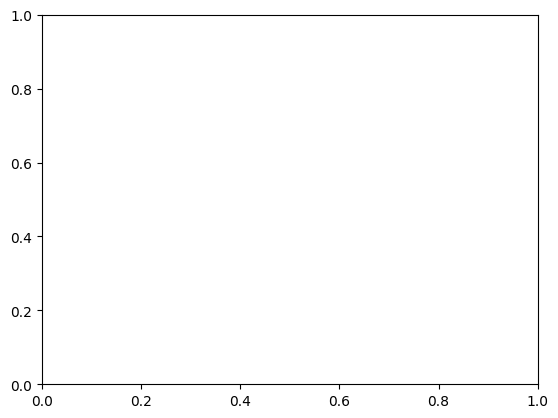

In [ ]:
# Collect histogram of initial event positions
xpos, ypos = [], []
for i in tqdm(range(len(bout))):
    chunk = df[df['eventId'] == i]
    if len(chunk) == 0:
        continue
    xpos.append(chunk.iloc[0]['preX_mm'])
    ypos.append(chunk.iloc[0]['preY_mm'])


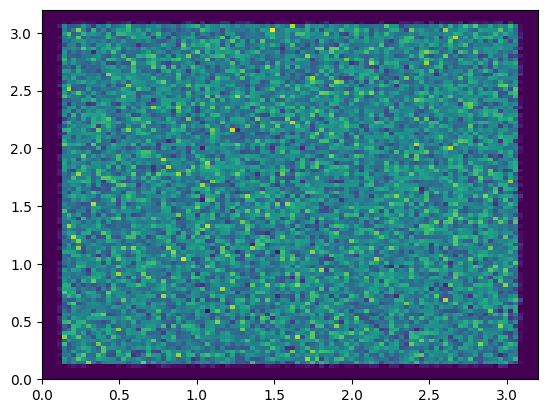

In [ ]:

plt.hist2d(xpos, ypos, bins=100, range=((0, 3.2), (0, 3.2)))
plt.show()

In [6]:
lookat =0

In [8]:
print(bout[bout['eventId'] == lookat])
print(df[df['eventId'] == lookat].to_string(index=False))
lookat += 1

       iScint  eventId   time_ns  energy_MeV
80368      36        1  0.090046       0.511
 eventId  trackId  parentId  step        process  preX_mm  preY_mm  preZ_mm  postX_mm  postY_mm  postZ_mm  Ekin_MeV  edep_MeV  time_ns  volume
       1        1         0     1 Transportation 2.068490  2.77255  -5.0000  2.068490   2.77255   -0.1000  0.511000  0.000000 0.016345 Encaps0
       1        1         0     2 Transportation 2.068490  2.77255  -0.1000  2.068490   2.77255    0.0000  0.511000  0.000000 0.016678   Scint
       1        1         0     3          compt 2.068490  2.77255   0.0000  2.068490   2.77255   12.3922  0.230041  0.000013 0.058014   Scint
       1        1         0     4           phot 2.068490  2.77255  12.3922  0.603906   1.35939   11.8664  0.000000  0.000000 0.065026   Scint
       1        5         1     1           phot 0.603906  1.35939  11.8664  0.635579   1.50176   11.8153  0.000000  0.000086 0.065541   Scint
       1       14         5     1           phot 0.6

8